## Logistic Regression And Feature Scaling

### 1. Dependencies

In [2]:
from prep import *
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_validate
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

X_train, X_test, y_train, y_test, meta = load_model_data()
y_train_bin, y_test_bin, thr = make_binary_target(y_train, y_test, quantile=0.5)

# Time-ordered folds with a 12-quarter validation block each, so the first training block is long
# enough (~4 years+) to contain both high and low quarters.
CV = TimeSeriesSplit(n_splits=4, test_size=12)

# scikit-learn >= 1.8 sets L1/L2 with l1_ratio only (penalty is deprecated); older versions need penalty="elasticnet"
NEW_API = tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 8)
def logit(**kw):
    kw.setdefault("max_iter", 20_000)
    if NEW_API:
        return LogisticRegression(solver="saga", **kw)
    return LogisticRegression(solver="saga", penalty="elasticnet", **kw)
print("scikit-learn", sklearn.__version__)

train 1992-03-31 to 2014-12-31  (92, 27)
test  2015-03-31 to 2025-12-31  (44, 27)
threshold = 1.050 (training 50% quantile); share above: train 50%, test 20%
scikit-learn 1.9.1


In [3]:
# class balance by period
pd.DataFrame({"train": y_train_bin.value_counts(normalize=True), "test": y_test_bin.value_counts(normalize=True)}) \
  .rename(index={0: "low (<= threshold)", 1: "high (> threshold)"}).round(2)

,train,test
co_other_cons,,
low (<= threshold),0.5,0.8
high (> threshold),0.5,0.2


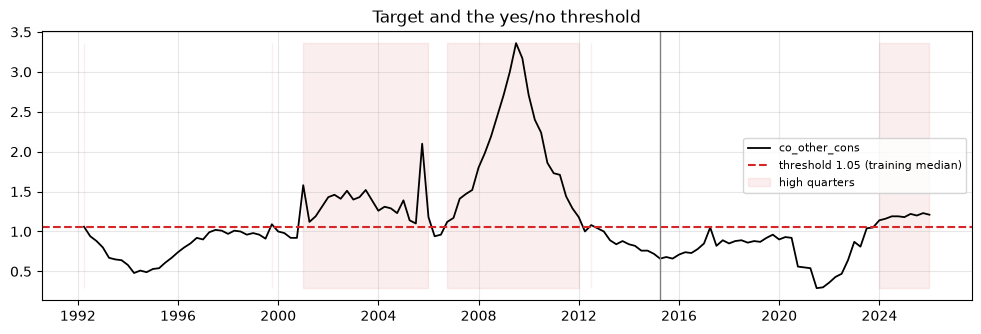

In [4]:
fig, ax = plt.subplots(figsize=(12, 3.5))
y_all = pd.concat([y_train, y_test])
ax.plot(y_all.index, y_all, color="black", lw=1.3, label=meta["target"])
ax.axhline(thr, color="tab:red", ls="--", label=f"threshold {thr:.2f} (training median)")
ax.axvline(X_test.index.min(), color="grey", lw=1)
ax.fill_between(y_all.index, y_all.min(), y_all.max(), where=y_all > thr, color="tab:red", alpha=0.08, label="high quarters")
ax.set_title("Target and the yes/no threshold"); ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.show()

### 2. Feature scaling experiment
Same logistic regression (default L2 penalty, C = 1) with four preprocessing choices. Only the scaling changes.

In [5]:
# the raw feature scales differ a lot (this is what the penalty "sees" without scaling)
rng = X_train.describe().T[["mean", "std", "min", "max"]]
rng.sort_values("std", ascending=False).round(3).head(12)

,mean,std,min,max
sent_consumer_L4,86.305,12.875,57.700,110.100
sent_consumer_L3,86.370,12.832,57.700,110.100
sent_consumer_L2,86.392,12.824,57.700,110.100
sent_consumer_L1,86.397,12.823,57.700,110.100
stk_vix_L1,20.508,8.219,10.595,58.694
stk_vix_L2,20.550,8.190,10.595,58.694
stk_vix_L3,20.607,8.153,10.595,58.694
stk_vix_L4,20.693,8.133,10.595,58.694
co_credit_card_L1,4.993,1.709,2.930,10.540
co_credit_card_L2,5.012,1.697,2.930,10.540


In [6]:
scalers = {"no scaling": "passthrough", "StandardScaler": StandardScaler(),
           "MinMaxScaler": MinMaxScaler(), "RobustScaler": RobustScaler()}
rows, coef_by_scaler = {}, {}
for name, sc in scalers.items():
    pipe = make_pipeline(SimpleImputer(strategy="median"), sc, LogisticRegression(max_iter=5000))
    cv = cross_validate(pipe, X_train, y_train_bin, cv=CV, scoring=["accuracy", "roc_auc"])
    pipe.fit(X_train, y_train_bin)
    lr = pipe[-1]
    rows[name] = {"CV accuracy": cv["test_accuracy"].mean(), "CV ROC AUC": np.nanmean(cv["test_roc_auc"]),
                  "test accuracy": (pipe.predict(X_test) == y_test_bin).mean(),
                  "iterations to converge": int(lr.n_iter_[0]),
                  "largest |coef|": np.abs(lr.coef_).max(), "smallest |coef|": np.abs(lr.coef_).min()}
    coef_by_scaler[name] = pd.Series(lr.coef_.ravel(), index=X_train.columns)
scaling_results = pd.DataFrame(rows).T.round(3)
scaling_results

/home/codespace/.local/lib/python3.14/site-packages/sklearn/metrics/_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/home/codespace/.local/lib/python3.14/site-packages/sklearn/metrics/_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/home/codespace/.local/lib/python3.14/site-packages/sklearn/metrics/_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/home/codespace/.local/lib/python3.14/site-packages/sklearn/metrics/_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/home/codespace/.local/lib/python3.14/site-packages/sklearn/metrics/_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined i

,CV accuracy,CV ROC AUC,test accuracy,iterations to converge,largest |coef|,smallest |coef|
no scaling,0.562,0.514,0.795,648.0,2.904,0.000
StandardScaler,0.521,0.668,0.864,17.0,1.933,0.083
MinMaxScaler,0.521,0.468,0.909,16.0,1.865,0.011
RobustScaler,0.542,0.693,0.864,14.0,2.021,0.020


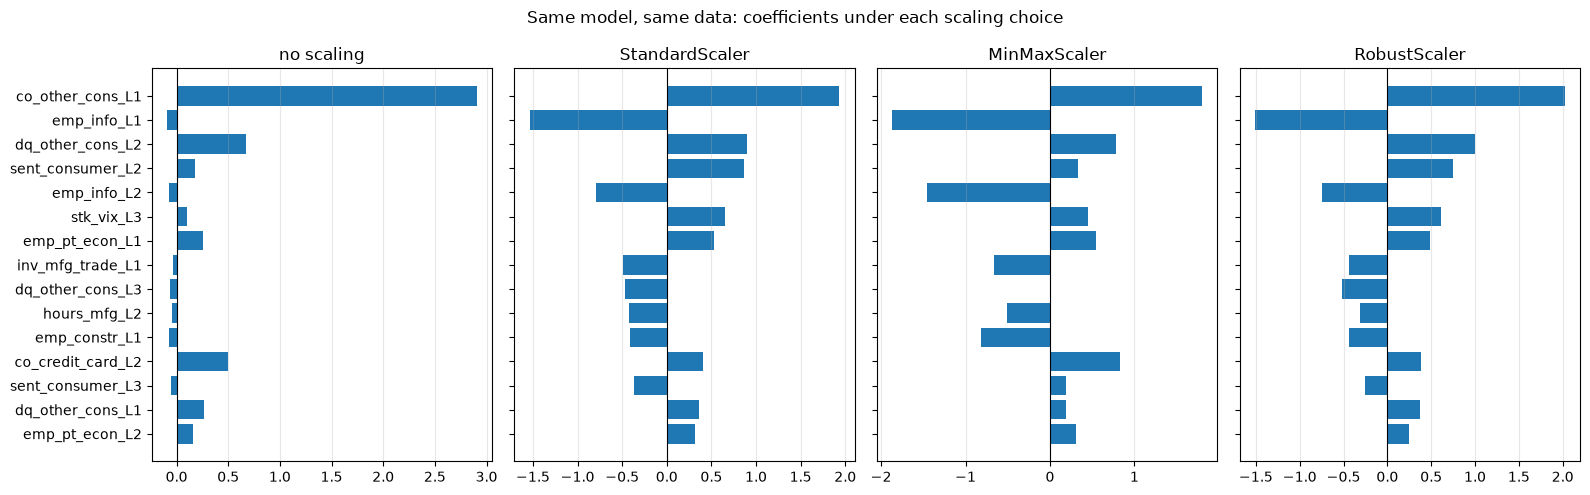

In [7]:
coefs_sc = pd.DataFrame(coef_by_scaler)
top = coefs_sc["StandardScaler"].abs().sort_values(ascending=False).index[:15]
fig, axes = plt.subplots(1, 4, figsize=(16, 5), sharey=True)
for ax, name in zip(axes, coefs_sc.columns):
    ax.barh(top[::-1], coefs_sc.loc[top[::-1], name], color="tab:blue")
    ax.axvline(0, color="black", lw=0.8); ax.set_title(name); ax.grid(axis="x", alpha=0.3)
fig.suptitle("Same model, same data: coefficients under each scaling choice")
plt.tight_layout(); plt.show()

> **Note:** without scaling, coefficient sizes reflect each feature's *units*, not its importance, and the penalty shrinks them unevenly, so rankings change. StandardScaler (mean 0, sd 1) makes coefficients comparable ("per 1 sd"); MinMaxScaler squeezes to 0–1 (sensitive to extreme quarters like 2008 or 2020); RobustScaler uses the median and middle 50%, so outliers matter less. More iterations (or a convergence warning) without scaling shows the optimizer struggling. <br> StandardScaler is used for the rest of the notebook (via `preprocess(scale=True)`).

### 3. Tuned logistic regression (penalty type and strength)
- `C`: inverse penalty strength (small C = strong penalty = simpler model).
- `l1_ratio`: 0 = L2 (Ridge-like shrinkage), 1 = L1 (Lasso-like, sets coefficients to 0), 0.5 = mix.

In [10]:
log_pipe = make_pipeline(*preprocess(scale=True), logit())
log_grid = {"logisticregression__C": np.logspace(-3, 2, 20),
            "logisticregression__l1_ratio": [0.0, 0.5, 1.0]}
# accuracy instead of ROC AUC: some 12-quarter validation blocks contain only high or only low
# quarters (the rate stays on one side of the median for years), where ROC AUC is undefined
log_search = tune(log_pipe, log_grid, X_train, y_train_bin, cv=CV, scoring="accuracy")
log_best = log_search.best_estimator_
best_C = log_search.best_params_["logisticregression__C"]
best_l1 = log_search.best_params_["logisticregression__l1_ratio"]

best params: {'logisticregression__C': np.float64(0.23357214690901212), 'logisticregression__l1_ratio': 1.0}
best CV accuracy: 0.6042


> **Note:** Tuned on accuracy, because some validation blocks contain only one class, where ROC AUC can’t be computed.

<Axes: title={'center': 'Tuning: C by l1_ratio'}, xlabel='C', ylabel='accuracy'>

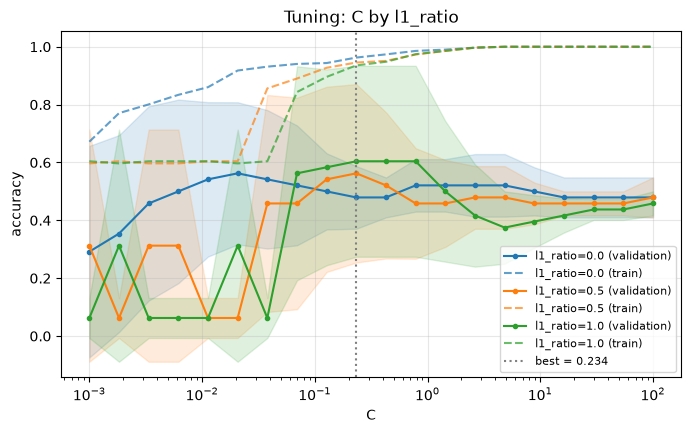

In [11]:
plot_tuning(log_search, "logisticregression__C", by="logisticregression__l1_ratio")

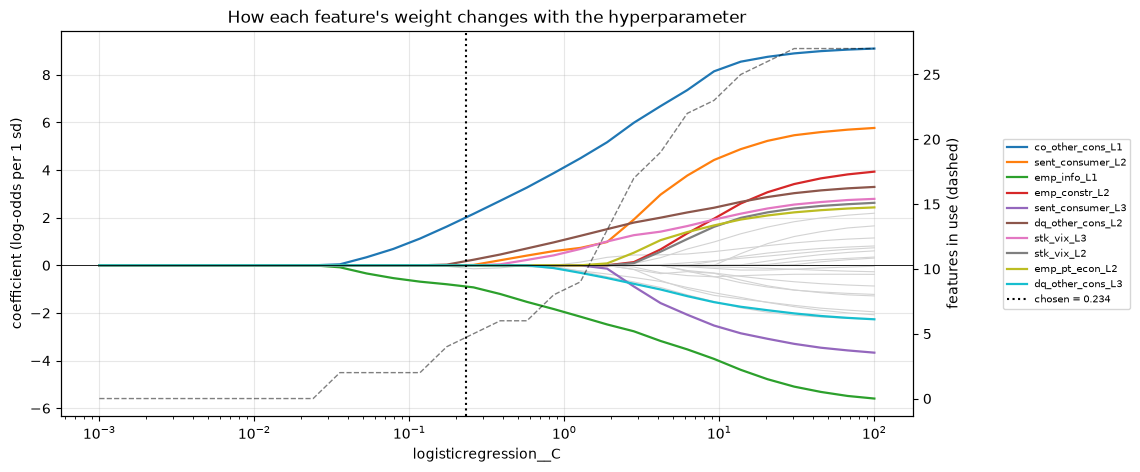

In [12]:
path_log = weight_path(make_pipeline(*preprocess(scale=True), logit(l1_ratio=best_l1)),
                       "logisticregression__C", np.logspace(-3, 2, 30), X_train, y_train_bin)
ax = plot_weight_path(path_log, best=best_C)
ax.set_ylabel("coefficient (log-odds per 1 sd)")
plt.show()

> **Note:** Read left to right this time: small C (strong penalty) keeps coefficients at or near 0; larger C lets them grow.

### 4. Classification Accuracy

In [13]:
score_classifier(log_best, X_train, X_test, y_train_bin, y_test_bin)

,Accuracy,Precision,Recall,F1,ROC_AUC,n
train (in-sample),0.924,0.953,0.891,0.921,0.972,92.0
test,0.932,0.750,1.000,0.857,0.952,44.0
always-majority - test,0.795,NaN,NaN,NaN,NaN,44.0


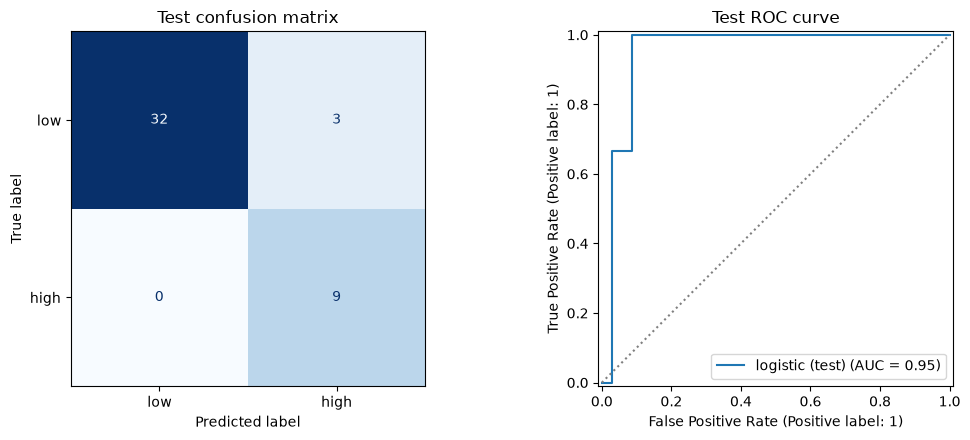

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_estimator(log_best, X_test, y_test_bin, display_labels=["low", "high"],
                                      cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Test confusion matrix")
if y_test_bin.nunique() > 1:
    RocCurveDisplay.from_estimator(log_best, X_test, y_test_bin, ax=axes[1], name="logistic (test)")
    axes[1].plot([0, 1], [0, 1], ls=":", color="grey")
    axes[1].set_title("Test ROC curve")
plt.tight_layout(); plt.show()

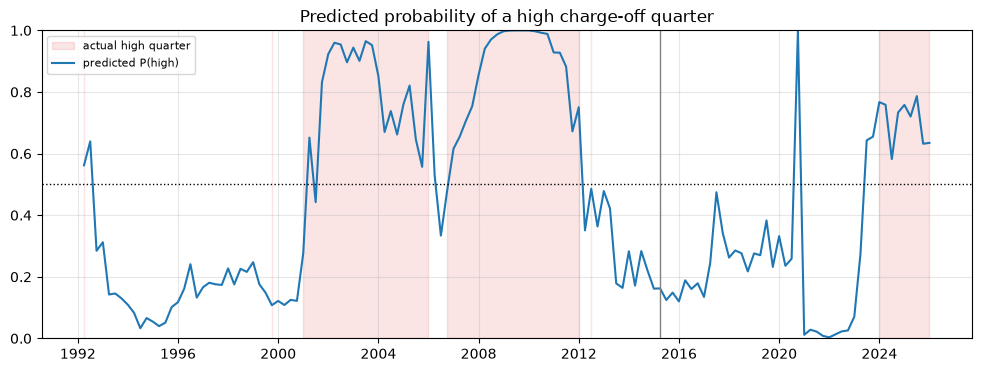

In [17]:
# predicted probability of a high quarter over time
X_all = pd.concat([X_train, X_test]); yb_all = pd.concat([y_train_bin, y_test_bin])
proba = pd.Series(log_best.predict_proba(X_all)[:, 1], index=X_all.index)
fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(yb_all.index, 0, 1, where=yb_all == 1, step="mid", color="tab:red", alpha=0.12, label="actual high quarter")
ax.plot(proba.index, proba, color="tab:blue", lw=1.5, label="predicted P(high)")
ax.axhline(0.5, color="black", ls=":", lw=1)
ax.axvline(X_test.index.min(), color="grey", lw=1)
ax.set_ylim(0, 1); ax.set_title("Predicted probability of a high charge-off quarter")
ax.legend(fontsize=8, loc="upper left"); ax.grid(alpha=0.3); plt.show()

### 5. What Drives the Prediction

In [18]:
lw = feature_weights(log_best, X_train)
lw["odds ratio per 1 sd"] = np.exp(lw["weight"])
print(f"C = {best_C:.3g}, l1_ratio = {best_l1}; {int(lw['used'].sum())} of {len(lw)} features used")
lw[lw["used"]].head(15).round(3)

C = 0.234, l1_ratio = 1.0; 4 of 27 features used


,feature,weight,abs weight,used,variable,odds ratio per 1 sd
0,co_other_cons_L1,2.014,2.014,True,co_other_cons,7.495
1,emp_info_L1,-0.883,0.883,True,emp_info,0.414
2,dq_other_cons_L2,0.180,0.180,True,dq_other_cons,1.197
3,hours_mfg_L1,-0.127,0.127,True,hours_mfg,0.880


> **Note**: An odds ratio of 1.8 means a 1-sd higher value of that feature multiplies the odds of a high charge-off quarter by 1.8; 0.6 means it cuts the odds by 40%.

<Axes: title={'center': 'Logistic: coefficients (log-odds per 1 sd)'}>

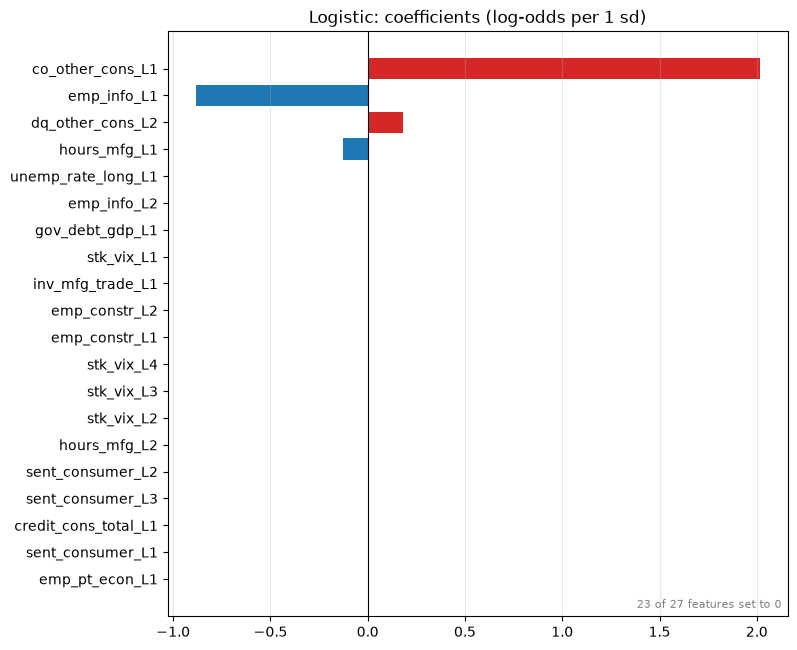

In [19]:
plot_feature_weights(log_best, X_train, top=20, title="Logistic: coefficients (log-odds per 1 sd)")

### 6. Overfitting

,full-training weight,mean across folds,sd across folds,share of folds used,sign flips
feature,,,,,
co_other_cons_L1,2.014,1.102,0.677,1.00,False
emp_info_L1,-0.883,-0.654,0.368,1.00,False
dq_other_cons_L2,0.180,0.001,0.001,0.25,False
hours_mfg_L1,-0.127,-0.121,0.144,0.75,False
emp_constr_L1,0.000,-0.061,0.122,0.25,False
hours_mfg_L2,0.000,-0.039,0.076,0.50,False
house_cs10_L1,0.000,0.180,0.359,0.25,False
stk_vix_L4,0.000,0.131,0.263,0.25,False


<Axes: title={'center': 'Weight stability across time folds (dots = folds, bar = full training)'}>

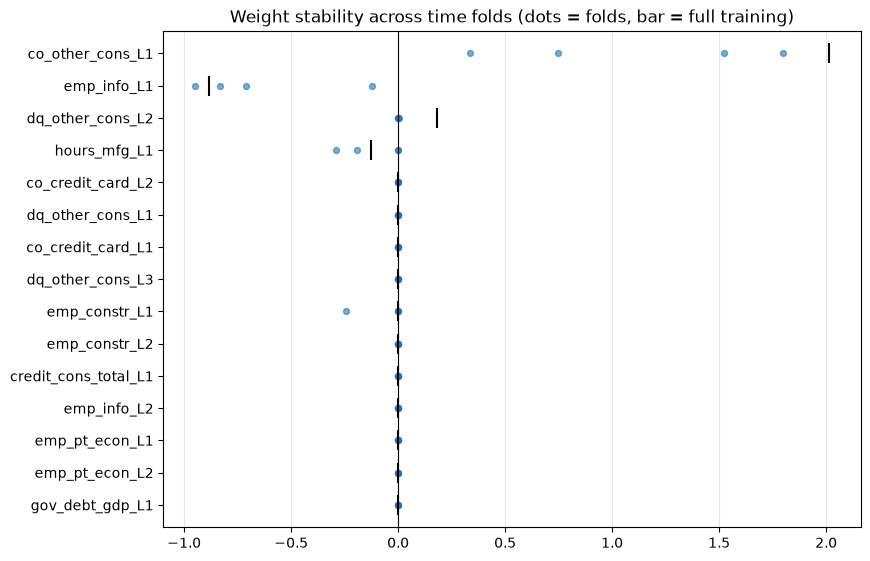

In [20]:
W_log, stab_log = weight_stability(log_best, X_train, y_train_bin, cv=CV)
display(stab_log[stab_log["share of folds used"] > 0].head(15).round(3))
plot_weight_stability(W_log, top=15)

<Axes: title={'center': 'Permutation importance (big train, small test = likely overfit)'}, xlabel='drop in roc_auc when shuffled'>

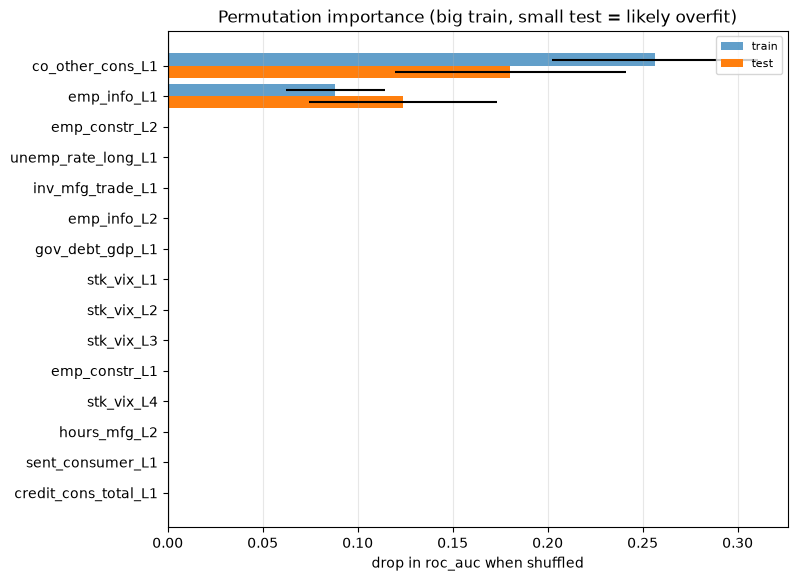

In [21]:
perm_log = permutation_table(log_best, X_train, y_train_bin, X_test, y_test_bin, n_repeats=20, scoring="roc_auc")
plot_permutation(perm_log, top=15)

In [22]:
record("Logistic", log_best, X_train, X_test, y_train_bin, y_test_bin, search=log_search,
       notes=f"high = above training median {thr:.3f}; C={best_C:.3g}, l1_ratio={best_l1}")

recorded 'Logistic' -> /workspaces/DX799-O1/model_data/results


,Accuracy,Precision,Recall,F1,ROC_AUC,n
train (in-sample),0.924,0.953,0.891,0.921,0.972,92.0
test,0.932,0.750,1.000,0.857,0.952,44.0
always-majority - test,0.795,NaN,NaN,NaN,NaN,44.0


### 7. Compare to All Models
Regression models are scored by whether their forecast lands on the correct side of the threshold.

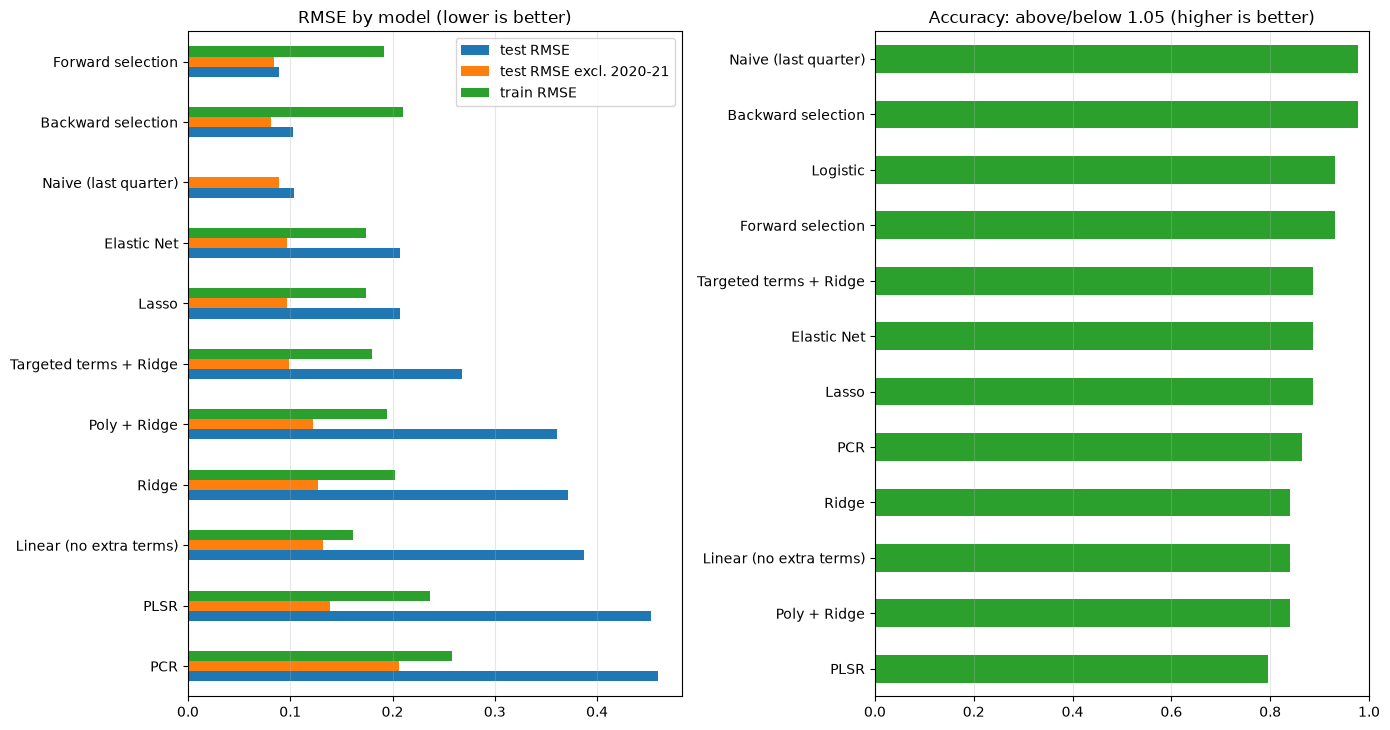

,type,test RMSE,test MAE,test R2,test DirAcc,test RMSE excl. 2020-21,train RMSE,overfit gap (test - train RMSE),Accuracy (vs threshold),CV score,CV metric,best params,saved,test ROC_AUC
Forward selection,regressor,0.089,0.065,0.878,0.659,0.084,0.192,-0.103,0.931818,0.22666,root_mean_squared_error,{'sequentialfeatureselector__n_features_to_sel...,2026-10-18 03:17,NaN
Backward selection,regressor,0.103,0.063,0.836,0.636,0.081,0.21,-0.107,0.977273,0.235818,root_mean_squared_error,{'sequentialfeatureselector__n_features_to_sel...,2026-10-18 03:17,NaN
Naive (last quarter),baseline,0.104,0.066,0.832,NaN,0.089,NaN,NaN,0.977273,NaN,NaN,NaN,NaN,NaN
Elastic Net,regressor,0.207,0.114,0.34,0.636,0.097,0.174,0.033,0.886364,0.336756,root_mean_squared_error,"{'elasticnet__alpha': 0.019573417814876617, 'e...",2026-10-18 02:11,NaN
Lasso,regressor,0.207,0.114,0.339,0.636,0.097,0.174,0.033,0.886364,0.336352,root_mean_squared_error,{'lasso__alpha': 0.020309176209047347},2026-10-18 02:06,NaN
Targeted terms + Ridge,regressor,0.268,0.139,-0.109,0.614,0.099,0.18,0.088,0.886364,0.353107,root_mean_squared_error,"{'addterms__pairs': (('dq_other_cons_L1', 'une...",2026-10-18 01:43,NaN
Poly + Ridge,regressor,0.361,0.157,-1.014,0.636,0.122,0.195,0.166,0.840909,0.38412,root_mean_squared_error,"{'polynomialfeatures__degree': 1, 'polynomialf...",2026-10-18 01:10,NaN
Ridge,regressor,0.372,0.169,-1.138,0.614,0.127,0.202,0.17,0.840909,0.384148,root_mean_squared_error,{'ridge__alpha': 32.57020655659783},2026-10-18 02:00,NaN
Linear (no extra terms),regressor,0.387,0.179,-1.307,0.591,0.132,0.161,0.226,0.840909,None,None,None,2026-10-18 01:10,NaN
PLSR,regressor,0.453,0.2,-2.168,0.614,0.139,0.237,0.216,0.795455,0.389209,root_mean_squared_error,{'plsregression__n_components': 2},2026-10-18 03:22,NaN


In [23]:
compare(threshold=thr)

### 7. Target Change (Predicting Rise Next Quarter)
"Above the median" is easy when the rate is persistent: last quarter's level nearly answers it. "Will it **rise** vs last quarter?" removes that advantage. This is exploratory and not recorded (its accuracy is on a different question), but it can be compared with the **DirAcc** of the regression models in the table above.

In [24]:
lag_col = f"{meta['target']}_L1"
y_train_up = (y_train > X_train[lag_col]).astype(int)
y_test_up = (y_test > X_test[lag_col]).astype(int)
print(f"share of quarters with a rise: train {y_train_up.mean():.0%}, test {y_test_up.mean():.0%}")

up_search = tune(make_pipeline(*preprocess(scale=True), logit()),
                 {"logisticregression__C": np.logspace(-3, 2, 20), "logisticregression__l1_ratio": [0.0, 1.0]},
                 X_train, y_train_up, cv=CV, scoring="accuracy")
score_classifier(up_search.best_estimator_, X_train, X_test, y_train_up, y_test_up)

share of quarters with a rise: train 45%, test 59%
best params: {'logisticregression__C': np.float64(0.23357214690901212), 'logisticregression__l1_ratio': 0.0}
best CV accuracy: 0.7708


,Accuracy,Precision,Recall,F1,ROC_AUC,n
train (in-sample),0.826,0.821,0.780,0.800,0.905,92.0
test,0.636,0.692,0.692,0.692,0.558,44.0
always-majority - test,0.591,NaN,NaN,NaN,NaN,44.0


<Axes: title={'center': 'Direction model: coefficients'}>

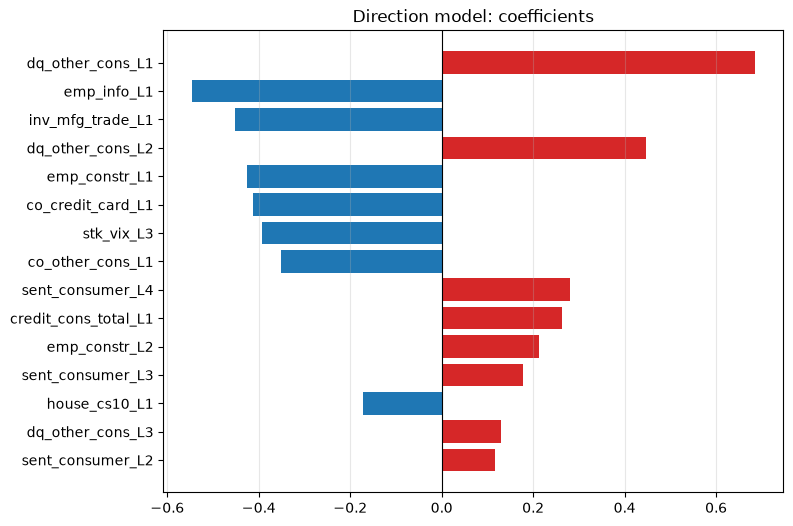

In [25]:
plot_feature_weights(up_search.best_estimator_, X_train, top=15, title="Direction model: coefficients")

### 8. Export Results

In [26]:
export_predictions(log_best, X_train, X_test, y_train_bin, y_test_bin, name="Logistic")
scaling_results.to_csv(f"{EXPORT_DIR}/nb4_scaling_experiment.csv")
lw.to_csv(f"{EXPORT_DIR}/nb4_logistic_coefficients.csv", index=False)

saved 136 rows -> /workspaces/DX799-O1/model_data/exports/Logistic_predictions.csv


### 9. Notes

**Goal:** turn the forecast into a yes/no question and use logistic regression to answer it, while showing why feature scaling matters.

**Target (yes/no):** will next quarter's `co_other_cons` be **above the training-period median**? ("high charge-off quarter"). The threshold comes from 1992–2014 only, so no test information is used. The same threshold lets every regression model from notebooks 1–3 be scored on the same yes/no accuracy in `compare(threshold=...)`.

**Logistic regression** models the *probability* of a high quarter: log-odds = b0 + b1·x1 + … . A coefficient is the change in log-odds per 1 sd of the feature; exp(coef) is the **odds ratio**.

**Why scaling matters here:** scikit-learn's logistic regression is **penalized by default** (C = 1/penalty strength). The penalty treats every coefficient the same, so if features are on different scales, large-unit features are barely penalized and small-unit ones are crushed. Some solvers also converge slowly or not at all on unscaled data. Section 2 tests this directly.

**Lags:** same lagged features as before; with a persistent target, `co_other_cons_L1` will likely dominate (last quarter high → this quarter likely high). Section 7 adds a harder target (direction of change) where persistence helps less.

- **Feature scaling:** the experiment table (accuracy, convergence, coefficient ranges) and coefficient panels show why scaling is required for a penalized logistic model.
- **Hyperparameters:** chosen C and l1_ratio; whether L1 removed features; the C weight path.
- **Interpretation:** odds ratios for the main features (e.g. higher delinquency last quarter multiplies the odds of a high charge-off quarter by X).
- **Expected vs unexpected:** the level-threshold target is dominated by persistence; the direction target is harder; compare its accuracy with the regression models' DirAcc.
- **Overfitting:** train vs test accuracy/AUC, stability across folds, permutation importance on train vs test.